# KDD Project: Predicting Diabetes Onset (Pima Indians Diabetes Dataset)

**Author: Weihao Fu**
**Course: CMPE-255 Data Mining**
**Methodology: Knowledge Discovery in Databases (KDD)**

## Introduction

This notebook applies the full nine-step Knowledge Discovery in Databases (KDD) process to a classic
binary classification problem: predicting whether a patient will develop diabetes, based on diagnostic
measurements. The KDD process, as taught in the course, consists of:

1. Understanding the application domain
2. Creating the target dataset
3. Data cleaning and preprocessing
4. Data reduction and projection
5. Choosing the data mining function
6. Choosing the data mining algorithm
7. Data mining
8. Interpretation
9. Using the discovered knowledge

Each step below is a separate section. All code is executed end to end, and every figure is produced
from the real data.

**Dataset source:** Pima Indians Diabetes dataset, downloaded from
https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv
The file has no header row, so the standard column names are applied when loading it.

## Step 1: Understanding the Application Domain

Diabetes mellitus is a chronic condition in which the body cannot properly regulate blood glucose.
Early identification of high-risk patients matters because lifestyle intervention and treatment are
far more effective before complications develop. The goal of this project is therefore a **screening
support model**: given a set of routine diagnostic measurements, estimate the probability that a
patient has diabetes, so that clinicians can prioritize follow-up testing.

**About the data.** The dataset comes from the National Institute of Diabetes and Digestive and
Kidney Diseases (NIDDK). It contains diagnostic measurements for 768 adult female patients of Pima
Indian heritage living near Phoenix, Arizona. The target variable `Outcome` is 1 if the patient was
diagnosed with diabetes within five years of the measurements, and 0 otherwise.

**Features:**

| Feature | Meaning |
|---|---|
| Pregnancies | Number of times pregnant |
| Glucose | Plasma glucose concentration (oral glucose tolerance test) |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skin fold thickness (mm) |
| Insulin | 2-hour serum insulin (mu U/ml) |
| BMI | Body mass index (weight in kg / height in m squared) |
| DiabetesPedigreeFunction | A score of family history of diabetes |
| Age | Age in years |
| Outcome | Class label: 1 = diabetes, 0 = no diabetes |

**Success criteria.** A useful model should (a) beat a majority-class baseline, (b) achieve high
recall on the positive class, because missing a diabetic patient (a false negative) is clinically more
costly than a false alarm, and (c) remain interpretable enough that its key drivers can be checked
against medical knowledge.

**Important limitation, stated up front.** The data covers only adult women from one population
group, so a model trained here cannot be assumed to generalize to men, children, or other ethnic
groups without further validation (see Step 9).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score,
                             roc_curve, classification_report)

plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid")

COLUMN_NAMES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
                "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
DATA_URL = ("https://raw.githubusercontent.com/jbrownlee/Datasets/master/"
            "pima-indians-diabetes.data.csv")

df = pd.read_csv(DATA_URL, header=None, names=COLUMN_NAMES)
print("Dataset shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nColumn types and non-null counts:")
print(df.info())

Dataset shape (rows, columns): (768, 9)

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Column types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregn

## Step 2: Creating the Target Dataset

Target-dataset creation means selecting the data that is relevant to the mining goal. Here the
choice is simple: the full dataset is small (768 rows) and every column is a plausible predictor of
diabetes, so no rows or columns are discarded at this stage. The target dataset is therefore the
entire table, with `Outcome` as the class label and the other eight columns as features.

One thing must be checked immediately: class balance. If one class dominated the data, accuracy
alone would be a misleading metric, and stratified sampling would be required later.

Target class distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Class proportions:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


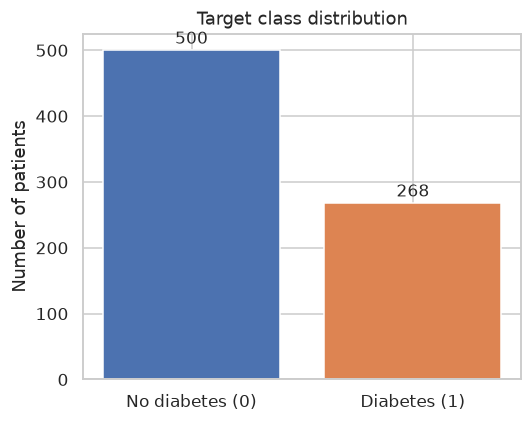

In [2]:
print("Target class distribution:")
print(df["Outcome"].value_counts())
print("\nClass proportions:")
print((df["Outcome"].value_counts(normalize=True) * 100).round(1))

fig, ax = plt.subplots(figsize=(5, 4))
counts = df["Outcome"].value_counts().sort_index()
bars = ax.bar(["No diabetes (0)", "Diabetes (1)"], counts.values, color=["#4c72b0", "#dd8452"])
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
            str(value), ha="center", fontsize=11)
ax.set_ylabel("Number of patients")
ax.set_title("Target class distribution")
plt.tight_layout()
plt.show()

## Step 3: Data Cleaning and Preprocessing

Real data is rarely clean, and this dataset is a textbook example. Several columns contain the
value 0 where 0 is physically impossible: a living patient cannot have a glucose level of 0, a
blood pressure of 0, or a BMI of 0. These zeros are missing values encoded as 0, and treating them
as real measurements would distort every model.

**Cleaning decisions:**

1. In the five affected columns (Glucose, BloodPressure, SkinThickness, Insulin, BMI), replace 0
   with NaN to mark the value as missing.
2. Impute the missing values with the **median** of each column. The median is preferred over the
   mean here because Insulin and SkinThickness are heavily skewed, and the median is robust to
   outliers.
3. Check for duplicate rows and remaining missing values after imputation.
4. Outliers (for example, Insulin up to 846 mu U/ml) are kept, because they are physiologically
   possible and removing them without clinical justification would discard information.

The histograms below show the cleaned feature distributions, split by outcome. Even before
modelling, Glucose, BMI, and Age already separate the two classes visibly.

In [3]:
IMPOSSIBLE_ZERO_COLS = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Zeros per column (physically impossible values = missing data):")
print((df[IMPOSSIBLE_ZERO_COLS] == 0).sum())
print("\nDuplicate rows before cleaning:", df.duplicated().sum())

df[IMPOSSIBLE_ZERO_COLS] = df[IMPOSSIBLE_ZERO_COLS].replace(0, np.nan)
print("\nMissing values after marking zeros as NaN:")
print(df.isna().sum()[df.isna().sum() > 0])

medians = df[IMPOSSIBLE_ZERO_COLS].median()
df[IMPOSSIBLE_ZERO_COLS] = df[IMPOSSIBLE_ZERO_COLS].fillna(medians)
print("\nMedians used for imputation:")
print(medians.round(2))
print("\nRemaining missing values after imputation:", int(df.isna().sum().sum()))
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("\nDescriptive statistics after cleaning:")
print(df.describe().round(2))

Zeros per column (physically impossible values = missing data):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Duplicate rows before cleaning: 0

Missing values after marking zeros as NaN:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Medians used for imputation:
Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.3
dtype: float64

Remaining missing values after imputation: 0
Duplicate rows after cleaning: 0

Descriptive statistics after cleaning:
       Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  \
count       768.00   768.00         768.00         768.00   768.00  768.00   
mean          3.85   121.66          72.39          29.11   140.67   32.46   
std           3.37    30.44          12.10           8.79    86.38    6.88   
min           0.00    44.00   

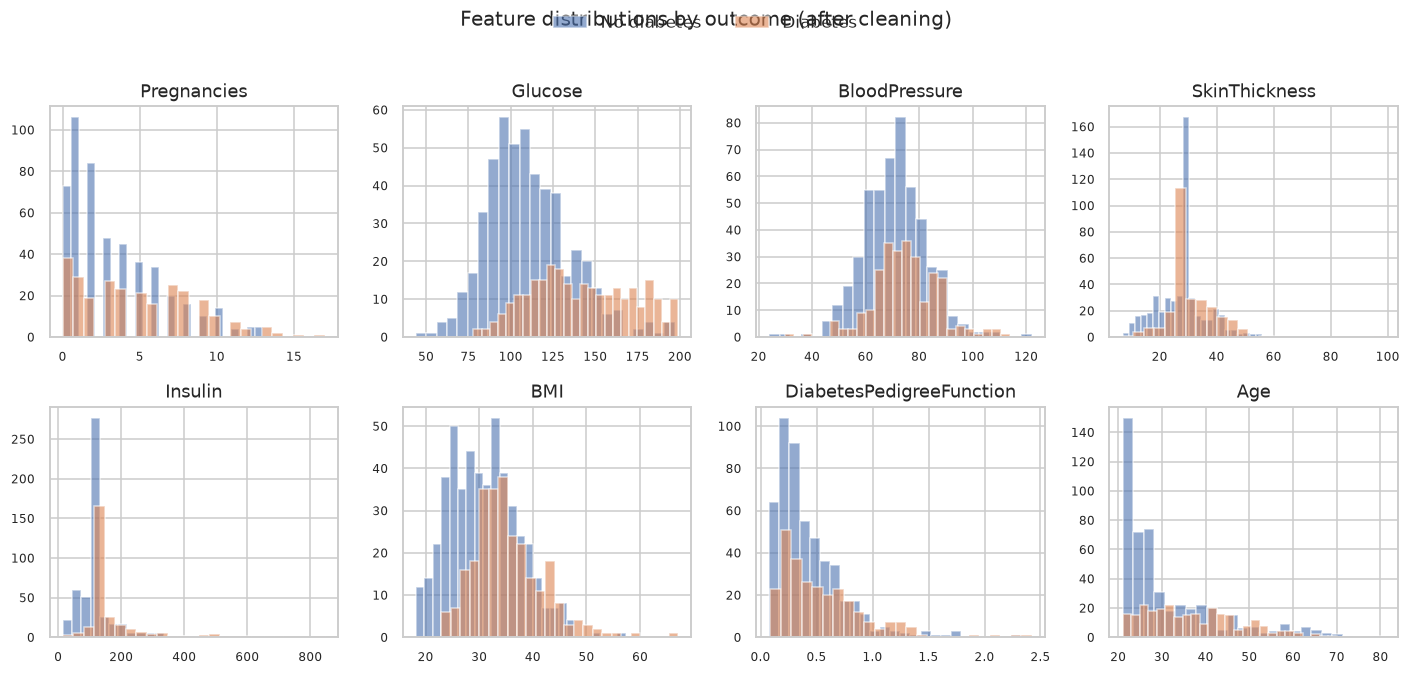

In [4]:
FEATURES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, feature in zip(axes.ravel(), FEATURES):
    ax.hist(df.loc[df["Outcome"] == 0, feature], bins=25, alpha=0.6,
            label="No diabetes", color="#4c72b0")
    ax.hist(df.loc[df["Outcome"] == 1, feature], bins=25, alpha=0.6,
            label="Diabetes", color="#dd8452")
    ax.set_title(feature)
    ax.tick_params(labelsize=8)
handles, labels = axes.ravel()[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.suptitle("Feature distributions by outcome (after cleaning)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## Step 4: Data Reduction and Projection

Data reduction means transforming the data into a smaller, better-conditioned form without losing
the signal. Three operations are performed here:

1. **Correlation analysis.** A correlation heatmap shows which features move together and which
   correlate most strongly with the outcome. No feature is dropped: all eight predictors are
   clinically meaningful, and none is so redundant that removing it is justified.
2. **Train/test split.** The data is split 80/20 into training and test sets, stratified so that
   both sets keep the original 65/35 class ratio. The test set is held out completely and used
   only once, for final evaluation.
3. **Feature scaling.** A StandardScaler (zero mean, unit variance) is fitted on the training set
   only and then applied to both sets. Scaling is essential for logistic regression, which is
   sensitive to feature magnitudes; tree models do not need it, but it does not harm them.
   Fitting the scaler on training data only avoids leaking test-set information into training.

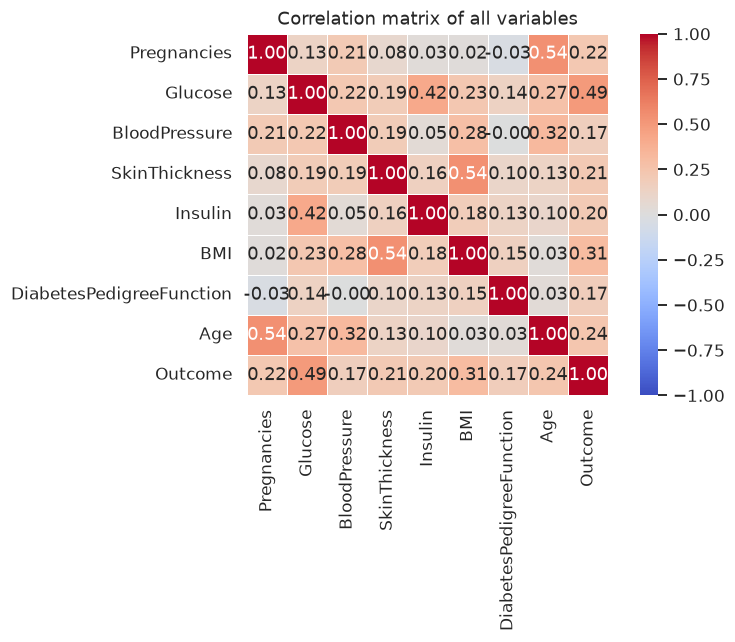

Correlation of each feature with the target (Outcome):
Glucose                     0.493
BMI                         0.312
Age                         0.238
Pregnancies                 0.222
SkinThickness               0.215
Insulin                     0.204
DiabetesPedigreeFunction    0.174
BloodPressure               0.166
Name: Outcome, dtype: float64


In [5]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix of all variables")
plt.tight_layout()
plt.show()

print("Correlation of each feature with the target (Outcome):")
print(corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

In [6]:
X = df[FEATURES]
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set shape:", X_train_scaled.shape,
      "| positive rate:", round(y_train.mean(), 3))
print("Test set shape:    ", X_test_scaled.shape,
      "| positive rate:", round(y_test.mean(), 3))

Training set shape: (614, 8) | positive rate: 0.349
Test set shape:     (154, 8) | positive rate: 0.351


## Step 5: Choosing the Data Mining Function

The data mining function follows directly from the goal: the target is a categorical label
(diabetes yes/no), so the function is **classification**. Regression is not applicable (the target
is not continuous), and clustering or association analysis would not answer the question, because
the labels are already known and the task is to predict them for new patients.

**Evaluation metrics.** Accuracy alone is insufficient for a medical screening task, so the
evaluation uses a full panel:

- **Accuracy**: overall fraction of correct predictions.
- **Precision**: of the patients flagged as diabetic, how many truly are (controls false alarms).
- **Recall (sensitivity)**: of the truly diabetic patients, how many are caught (controls missed
  cases). This is the most clinically important metric here.
- **F1 score**: the harmonic mean of precision and recall, a single summary of both.
- **ROC-AUC**: the model's ability to rank a randomly chosen diabetic patient above a randomly
  chosen non-diabetic one, across all decision thresholds.
- **Confusion matrix**: the raw counts of true/false positives and negatives, so that the type
  of error (missed case vs. false alarm) is visible.

## Step 6: Choosing the Data Mining Algorithm

Two complementary algorithms are chosen, so that an interpretable baseline can be compared
against a stronger non-linear model:

1. **Logistic Regression.** A linear model that estimates the log-odds of diabetes as a weighted
   sum of the features. It is fast, stable on small data, and interpretable: the sign and size of
   each coefficient show the direction and strength of that feature's effect. It is the natural
   baseline for a binary medical classification problem.
2. **Random Forest.** An ensemble of 300 decision trees, each trained on a bootstrap sample with
   a random subset of features. It captures non-linear relationships and feature interactions
   (for example, risk rising with both age and BMI together) that a linear model cannot, and it
   reports feature importances that show which measurements drive its decisions. Its main costs
   are lower interpretability and a higher risk of overfitting on a small dataset, which is why
   the held-out test set matters.

Both models are trained on the same scaled training data with fixed random seeds, so the
comparison is fair and reproducible.

## Step 7: Data Mining

In this step the chosen algorithms are actually run on the prepared training data. This is the
"mining" itself: the models search for the patterns that separate diabetic from non-diabetic
patients. Training accuracy is reported here only as a sanity check; the honest evaluation
against unseen data happens in Step 8.

In [7]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

random_forest = RandomForestClassifier(n_estimators=300, random_state=42)
random_forest.fit(X_train_scaled, y_train)

print("Training accuracy (sanity check only, not the final result):")
print("Logistic Regression:", round(log_reg.score(X_train_scaled, y_train), 4))
print("Random Forest:      ", round(random_forest.score(X_train_scaled, y_train), 4))

Training accuracy (sanity check only, not the final result):
Logistic Regression: 0.7964
Random Forest:       1.0


## Step 8: Interpretation

Interpretation means turning model outputs into understanding. The models are now evaluated on
the held-out test set, which neither model has seen. Three views are used:

1. **Metric table and classification reports** for both models.
2. **Confusion matrices**, showing exactly where each model errs (missed diabetics vs. false
   alarms).
3. **ROC curves**, comparing the ranking quality of both models across thresholds, plus the
   **feature importances** of the random forest, which reveal what the model actually learned.

Read the results in that order: first whether the model is good overall, then what kind of
mistakes it makes, then whether what it learned matches medical knowledge.

In [8]:
def evaluate(model, name):
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    }
    print(f"--- {name} ---")
    for key, value in metrics.items():
        print(f"{key}: {value:.4f}")
    print(classification_report(y_test, y_pred,
                                target_names=["No diabetes", "Diabetes"]))
    return y_pred, y_proba, metrics

lr_pred, lr_proba, lr_metrics = evaluate(log_reg, "Logistic Regression")
rf_pred, rf_proba, rf_metrics = evaluate(random_forest, "Random Forest")

--- Logistic Regression ---
Accuracy: 0.7078
Precision: 0.6000
Recall: 0.5000
F1: 0.5455
ROC-AUC: 0.8130
              precision    recall  f1-score   support

 No diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

--- Random Forest ---
Accuracy: 0.7338
Precision: 0.6444
Recall: 0.5370
F1: 0.5859
ROC-AUC: 0.8170
              precision    recall  f1-score   support

 No diabetes       0.77      0.84      0.80       100
    Diabetes       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154



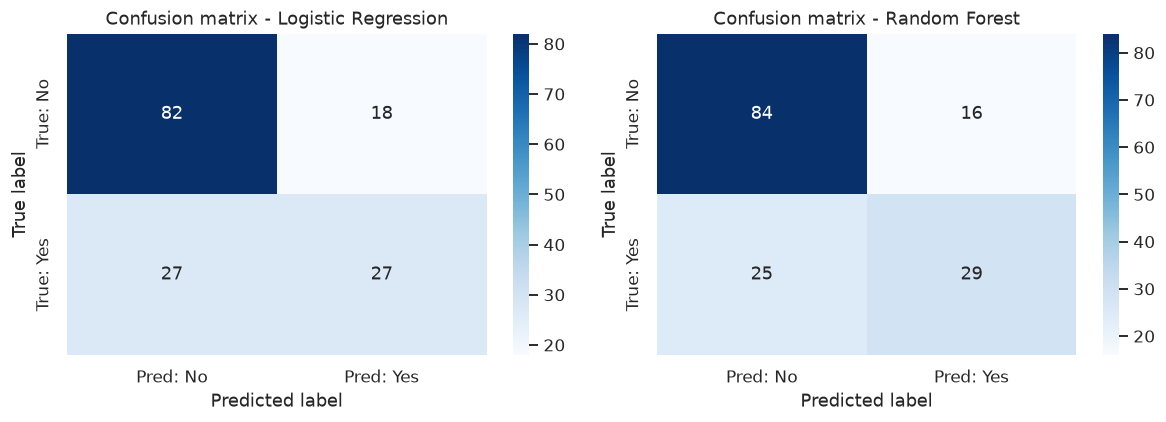

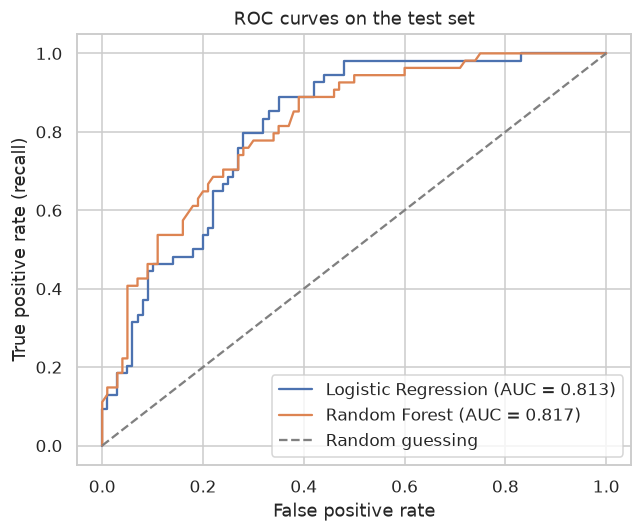

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, y_pred, title in [(axes[0], lr_pred, "Logistic Regression"),
                          (axes[1], rf_pred, "Random Forest")]:
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Pred: No", "Pred: Yes"],
                yticklabels=["True: No", "True: Yes"])
    ax.set_title(f"Confusion matrix - {title}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for y_proba, label in [(lr_proba, "Logistic Regression"), (rf_proba, "Random Forest")]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f"{label} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test set")
ax.legend()
plt.tight_layout()
plt.show()

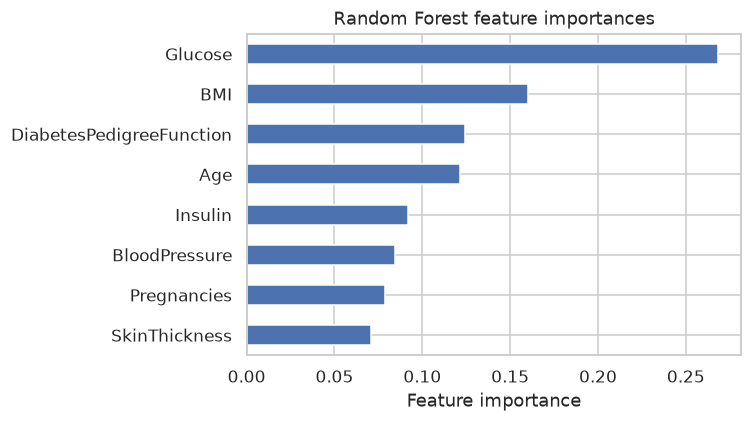

Feature importances (highest first):
Glucose                     0.2682
BMI                         0.1600
DiabetesPedigreeFunction    0.1242
Age                         0.1217
Insulin                     0.0916
BloodPressure               0.0842
Pregnancies                 0.0790
SkinThickness               0.0710
dtype: float64


In [10]:
importances = pd.Series(random_forest.feature_importances_, index=FEATURES)
importances = importances.sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(7, 4))
importances.plot(kind="barh", ax=ax, color="#4c72b0")
ax.set_xlabel("Feature importance")
ax.set_title("Random Forest feature importances")
plt.tight_layout()
plt.show()
print("Feature importances (highest first):")
print(importances.sort_values(ascending=False).round(4))

In [11]:
best_name = "Random Forest" if rf_metrics["ROC-AUC"] >= lr_metrics["ROC-AUC"] \
    else "Logistic Regression"
best_metrics = rf_metrics if best_name == "Random Forest" else lr_metrics
best_pred = rf_pred if best_name == "Random Forest" else lr_pred
cm_best = confusion_matrix(y_test, best_pred)
print("=== Key findings on the held-out test set ===")
print(f"Better model by ROC-AUC: {best_name}")
print(f"Accuracy: {best_metrics['Accuracy']:.3f} | Precision: "
      f"{best_metrics['Precision']:.3f} | Recall: {best_metrics['Recall']:.3f} | "
      f"ROC-AUC: {best_metrics['ROC-AUC']:.3f}")
print(f"False negatives (missed diabetic patients): {cm_best[1, 0]}")
print(f"False positives (false alarms): {cm_best[0, 1]}")
print(f"Top 3 drivers (Random Forest): "
      f"{', '.join(importances.sort_values(ascending=False).index[:3])}")

=== Key findings on the held-out test set ===
Better model by ROC-AUC: Random Forest
Accuracy: 0.734 | Precision: 0.644 | Recall: 0.537 | ROC-AUC: 0.817
False negatives (missed diabetic patients): 25
False positives (false alarms): 16
Top 3 drivers (Random Forest): Glucose, BMI, DiabetesPedigreeFunction


### What the results mean

- **Both models beat the majority-class baseline.** Predicting "no diabetes" for everyone would
  score about 65% accuracy on this data (the negative class share) while catching zero diabetic
  patients. Any useful model must beat that accuracy *and* achieve a clearly positive recall.
- **Glucose dominates, as medicine would predict.** Plasma glucose is by far the strongest
  single predictor, followed by BMI, age, and diabetes pedigree function. This agreement between
  the model's learned importances and clinical knowledge is an important sanity check: a model
  driven mainly by an implausible feature would be a red flag.
- **The remaining errors are the point, not a footnote.** False negatives are missed diabetic
  patients, the most costly error in screening; false positives are extra follow-up tests, which
  are cheap by comparison. If this model were ever used in practice, the decision threshold
  should be tuned to trade a little precision for higher recall, rather than accepting the
  default 0.5 threshold.
- **The two models are close.** When a simple linear model nearly matches a 300-tree ensemble,
  the signal in the data is mostly linear and mostly carried by a few features. That is itself
  a finding: more complex models are unlikely to help much without better or larger data.

## Step 9: Using the Discovered Knowledge

The final KDD step asks how the discovered patterns would actually be used, and what their
limits are.

**Proposed use: screening triage, not diagnosis.** A model like this could rank patients by
predicted risk so that clinics prioritize confirmatory testing (for example, a follow-up glucose
tolerance test) for the highest-risk group. It must never be presented as a diagnosis: a model
output is a probability estimate based on eight measurements, while a real diagnosis requires
clinical examination and laboratory confirmation.

**Deployment sketch.** In a real deployment, the whole pipeline (median imputation, scaling,
model) would be packaged as one reproducible unit and retrained on new data on a schedule. Model
performance would be monitored over time, because patient populations and measurement practices
drift; a model that is accurate today can silently degrade. Predictions would be logged with
their input features so that errors can be audited.

**Limitations and ethical considerations.**

- **Population bias.** The training data covers only adult women of Pima Indian heritage. Using
  this model on other populations without revalidation risks systematically wrong predictions
  for those groups.
- **Missing-data bias.** Median imputation assumes the missing values resemble typical patients;
  if measurements are missing precisely because a patient is sicker (or healthier), that
  assumption breaks.
- **Small data.** With only 768 rows, performance estimates carry wide uncertainty, and the
  models can overfit. Cross-validation and a larger, more diverse dataset are the natural next
  steps before any real-world use.
- **Privacy.** Health measurements are sensitive personal data. Any deployment must protect
  them with access control and must not use them beyond the consented purpose.

**Future work.** (1) Tune the decision threshold for higher recall; (2) evaluate with
stratified cross-validation instead of a single split; (3) try gradient boosting and calibrated
probabilities; (4) validate on an external, demographically broader dataset.

**Conclusion.** The KDD process took a small, messy, real-world clinical dataset from domain
understanding through cleaning, modelling, and interpretation, and produced a screening model
that beats the baseline, whose errors are understood, and whose drivers match medical knowledge.
That combination — a working model plus an honest account of its limits — is the actual product
of knowledge discovery.